# Lab 8 — Morphological Image Processing


---
## Theory — What is morphological processing?

**Morpholgical Processing** is modifying and improving the shapes in an image.

 The two ingredients of every morphological operation:

1. **The image** — a binary image where white (`255`) pixels are *foreground* (the object) and black (`0`) pixels are *background*.
2. **The structuring element** (also called *kernel* or *probe*) — a small shape (e.g., 3×3 square, 5×5 circle) that you slide across the image.

### The four basic operations
<img src="https://drive.google.com/thumbnail?id=129tujHkYNk3b8US7HEqbt-WymOZgwMnA&sz=w1000" width="600">



| Operation | What it does | Formula | Effect on objects |
|---|---|---|---|
| **Erosion** | Shrinks objects | $A \ominus B$ | Removes thin parts and noise |
| **Dilation** | Grows objects | $A \oplus B$ | Fills gaps, thickens objects |
| **Opening** | Erosion then dilation | $A \circ B = (A \ominus B) \oplus B$ | Removes small noise but keeps overall size |
| **Closing** | Dilation then erosion | $A \bullet B = (A \oplus B) \ominus B$ | Fills small holes but keeps overall size |

### How to remember each one

- **Erosion eats away** at object edges → output is smaller.
- **Dilation expands** object edges → output is larger.
- **Opening = "open up" the gaps** between separated noise specks (removes noise without shrinking real objects).
- **Closing = "close up" small holes** inside objects (fills gaps without growing real objects).



---
## Task 1 — Create a Binary Image with Shapes and Noise

The lab provides this code to generate a synthetic test image with **4 shapes** and some random **salt noise**:
- A solid filled circle on the left
- A solid filled rectangle
- A hollow (outline-only) circle
- A hollow rectangle
- Plus 1000 random scattered white pixels (noise)

## Setup — Import libraries

In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

%matplotlib inline

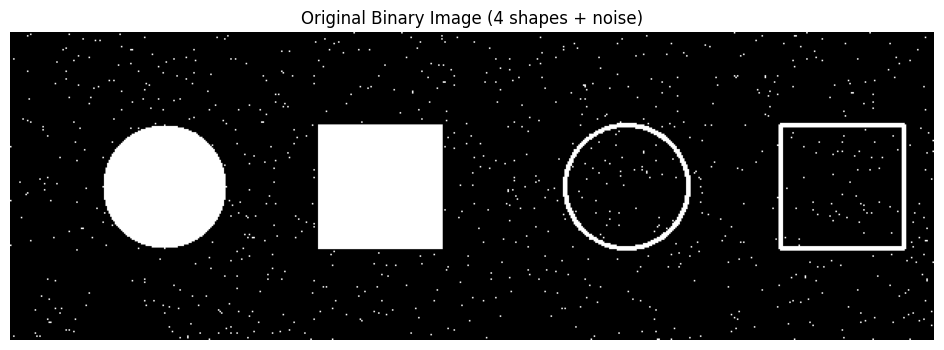

In [2]:
# Create a binary image with shapes and noise
image = np.zeros((200, 600), dtype=np.uint8)
cv2.circle(image, (100, 100), 40, 255, -1)              # Solid circle (filled) - radius=40
cv2.rectangle(image, (200, 60), (280, 140), 255, -1)    # Solid rectangle (filled) - start & end points= (200, 60), (280, 140)
cv2.circle(image, (400, 100), 40, 255, 2)               # Hollow circle (outline)
cv2.rectangle(image, (500, 60), (580, 140), 255, 2)     # Hollow rectangle (outline)

# Add small noise (1000 random white pixels)
np.random.seed(0)
for _ in range(1000):
    x, y = np.random.randint(0, 600), np.random.randint(0, 200)
    image[y, x] = 255

plt.figure(figsize=(12, 4))
plt.imshow(image, cmap='gray')
plt.title('Original Binary Image (4 shapes + noise)')
plt.axis('off')
plt.show()

---
Define the Structuring Element (5×5 Square Kernel)

The structuring element is the "shape" we slide across the image. The simplest one is a **square of all ones**:

$$K = \begin{bmatrix} 1 & 1 & 1 & 1 & 1 \\ 1 & 1 & 1 & 1 & 1 \\ 1 & 1 & 1 & 1 & 1 \\ 1 & 1 & 1 & 1 & 1 \\ 1 & 1 & 1 & 1 & 1 \end{bmatrix}$$

**Why a square?** It's directionally neutral (same effect horizontally and vertically) and fast to compute. The `1`s indicate which positions in the neighborhood are "active" — for a square kernel, every neighbor counts.

In [3]:
kernel = np.ones((5, 5), np.uint8)
print("Square kernel (5×5):")
print(kernel)

Square kernel (5×5):
[[1 1 1 1 1]
 [1 1 1 1 1]
 [1 1 1 1 1]
 [1 1 1 1 1]
 [1 1 1 1 1]]


---
## Assessment Task 1 — Apply Erosion, Dilation, Opening, Closing (Square Kernel)

For each operation we use a single OpenCV function:

| Operation | OpenCV call |
|---|---|
| Erosion | `cv2.erode(image, kernel, iterations=1)` |
| Dilation | `cv2.dilate(image, kernel, iterations=1)` |
| Opening | `cv2.morphologyEx(image, cv2.MORPH_OPEN, kernel)` |
| Closing | `cv2.morphologyEx(image, cv2.MORPH_CLOSE, kernel)` |



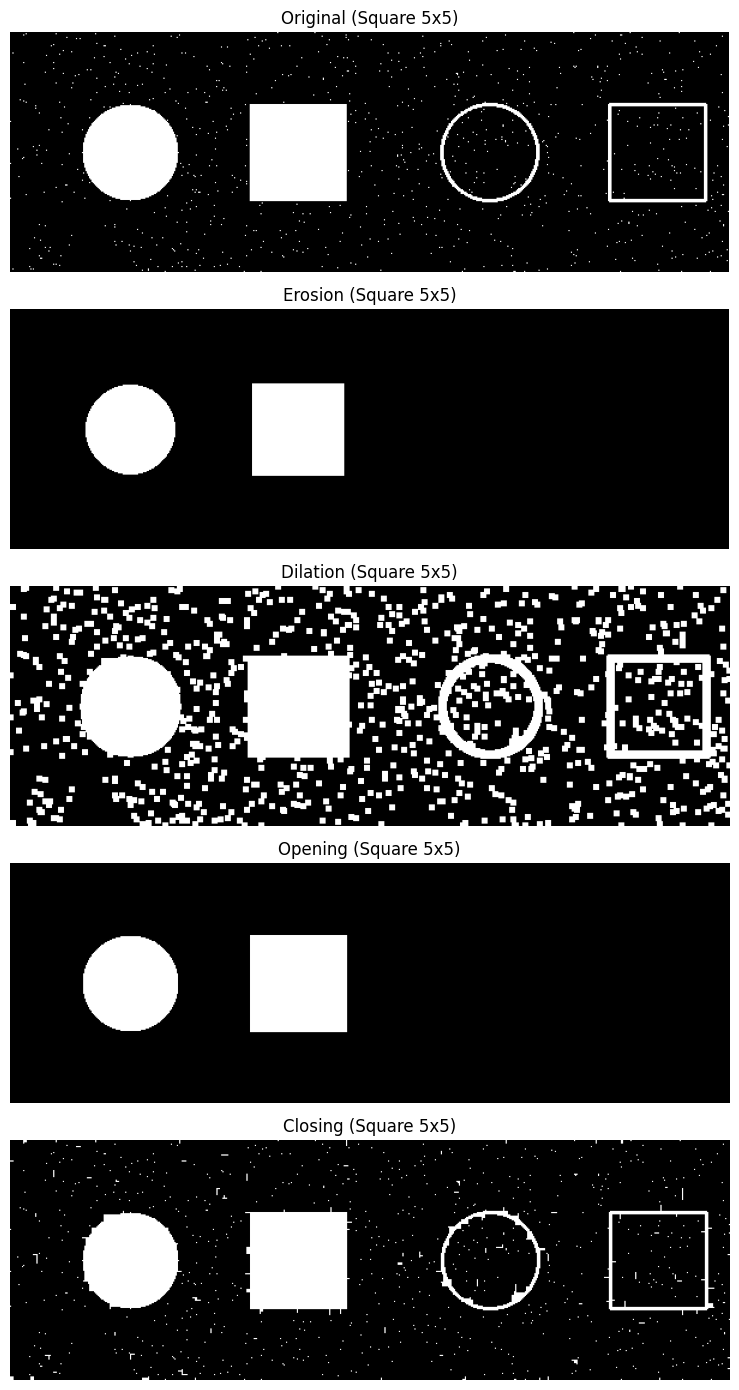

In [4]:
# Assessment Task 1 — Square 5x5 kernel
erosion_sq  = cv2.erode(image, kernel, iterations=1)
dilation_sq = cv2.dilate(image, kernel, iterations=1)
opening_sq  = cv2.morphologyEx(image, cv2.MORPH_OPEN, kernel)
closing_sq  = cv2.morphologyEx(image, cv2.MORPH_CLOSE, kernel)

results_sq = [image, erosion_sq, dilation_sq, opening_sq, closing_sq]
titles = ['Original', 'Erosion', 'Dilation', 'Opening', 'Closing']

fig, axes = plt.subplots(5, 1, figsize=(12, 14))
for ax, img, t in zip(axes, results_sq, titles):
    ax.imshow(img, cmap='gray')
    ax.set_title(f'{t} (Square 5x5)')
    ax.axis('off')
plt.tight_layout()
plt.show()

## Assessment Task 2 — Repeat with a Circular Kernel

Apply erosion, dilation opening and closing to the generated image in Task#1 using the following structuring element:

In [5]:
def circular_structuring_element(radius):
    """Creates a binary circular structuring element (exact circle)"""
    size = 2 * radius + 1                    # Ensure kernel size is odd
    kernel = np.zeros((size, size), dtype=np.uint8)
    cv2.circle(kernel, (radius, radius), radius, 1, -1)  # Draw filled circle
    return kernel

# Define radius
radius = 5
circle_kernel = circular_structuring_element(radius)


[[0 0 0 0 0 1 0 0 0 0 0]
 [0 0 1 1 1 1 1 1 1 0 0]
 [0 1 1 1 1 1 1 1 1 1 0]
 [0 1 1 1 1 1 1 1 1 1 0]
 [0 1 1 1 1 1 1 1 1 1 0]
 [1 1 1 1 1 1 1 1 1 1 1]
 [0 1 1 1 1 1 1 1 1 1 0]
 [0 1 1 1 1 1 1 1 1 1 0]
 [0 1 1 1 1 1 1 1 1 1 0]
 [0 0 1 1 1 1 1 1 1 0 0]
 [0 0 0 0 0 1 0 0 0 0 0]]


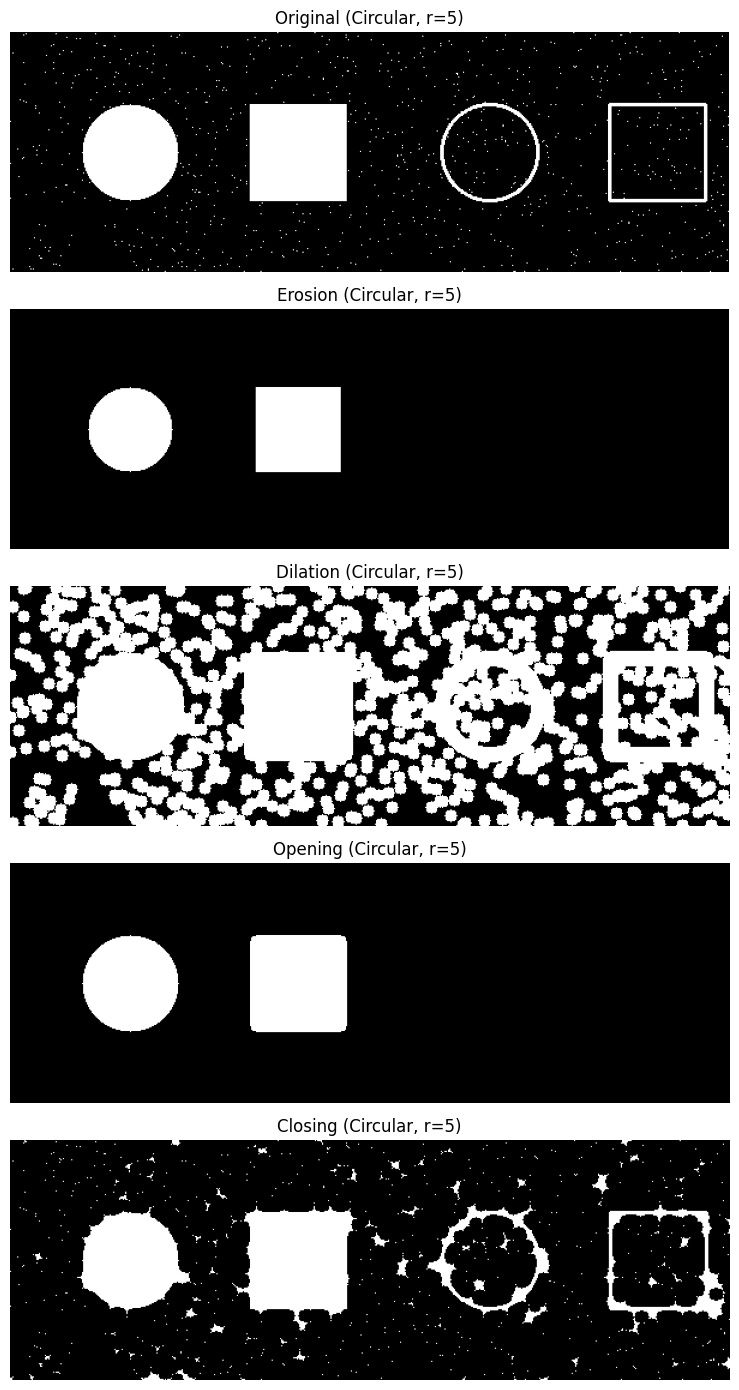

Operation   Square 5x5  Circle r=5
Original         14165       14165
Erosion          10335        8903
Dilation         35685       67938
Opening          11583       11547
Closing          14707       17834


In [6]:
# Assessment Task 2 — Circular kernel (radius = 5 -> 11x11)
print(circle_kernel)

erosion_ci  = cv2.erode(image, circle_kernel, iterations=1)
dilation_ci = cv2.dilate(image, circle_kernel, iterations=1)
opening_ci  = cv2.morphologyEx(image, cv2.MORPH_OPEN, circle_kernel)
closing_ci  = cv2.morphologyEx(image, cv2.MORPH_CLOSE, circle_kernel)

results_ci = [image, erosion_ci, dilation_ci, opening_ci, closing_ci]

fig, axes = plt.subplots(5, 1, figsize=(12, 14))
for ax, img, t in zip(axes, results_ci, titles):
    ax.imshow(img, cmap='gray')
    ax.set_title(f'{t} (Circular, r=5)')
    ax.axis('off')
plt.tight_layout()
plt.show()

# Side-by-side count of white pixels (to compare quantitatively)
print(f"{'Operation':<10}{'Square 5x5':>12}{'Circle r=5':>12}")
for t, a, b in zip(titles, results_sq, results_ci):
    print(f"{t:<10}{int((a>0).sum()):>12}{int((b>0).sum()):>12}")

## Assessment Task 3 — Difference Between Square vs Circular Kernel

 In your own words, explain the difference between the results in Task#1 and Task#2



### Answer — Square vs Circular Kernel

**Kernel size:** the square kernel is 5×5, while the circular kernel (radius 5) is 11×11, so it is much larger. This changes the results as much as the shape does.

| Operation | Square 5×5 | Circular (r = 5) |
|---|---|---|
| **Erosion** | Removes all the salt noise. Solid shapes shrink by 2 px per side and keep sharp corners. The 2-px outlines of the hollow circle and rectangle disappear completely. | Also removes all noise and the outlines. Solid shapes shrink more (5 px per side): white pixels dropped from 14165 to 8903, versus 10335 for the square. |
| **Dilation** | Every noise pixel becomes a small 5×5 square. Shapes grow slightly and keep sharp corners. | Every noise pixel becomes a large round blob (11×11) and many blobs merge together. White area rises to 67938 pixels (35685 for the square). Corners of the rectangles become rounded. |
| **Opening** | Removes the noise and keeps the solid circle and rectangle at almost their original size (11583 px). Outlines are lost because they are thinner than the kernel. | Removes the noise and keeps the solid shapes (11547 px), but rounds the corners of the rectangle. Outlines are lost. |
| **Closing** | Fills very small gaps. Noise stays as tiny dots with small streaks, and the outlines survive. White area: 14707 px. | Noise dots grow and merge into large round blobs that attach to the shapes and distort them. White area: 17834 px. Outlines survive but are cluttered. |

**Key differences**

1. **Shape of the effect:** a square kernel preserves straight edges and sharp corners (good for the rectangles). A circular kernel acts equally in all directions (isotropic), so it rounds corners and keeps circular shapes smooth.
2. **Strength of the effect:** because the circular kernel is larger (11×11), erosion and dilation change the objects more, and the noise blobs created by dilation and closing are much bigger.
3. **Noise removal:** both kernels remove the noise with erosion and opening. The square one does it with less damage to the shapes; the circular one rounds the rectangle corners.
4. **Thin structures:** both kernels are wider than the 2-px outlines, so the hollow shapes are removed by erosion and opening in both cases.
5. **Which to use:** a square kernel is fast and suits rectangular objects. A circular kernel suits round objects and gives direction-independent results, but its size should be chosen carefully so it does not round off or merge real features.